In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

In [6]:
rfm_scaled = pd.read_csv(
    "../data/processed/customer_rfm_scaled.csv",
    index_col="CustomerID"
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [7]:
segments = pd.read_csv(
    "../data/processed/customer_segments.csv",
    index_col="CustomerID"
)

labels = segments["Cluster"]

print(labels.value_counts())

Cluster
1    1622
3    1166
2     837
0     713
Name: count, dtype: int64


In [8]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"],
    index=rfm_scaled.index
)

pca_df["Cluster"] = labels

pca_df.head()

,PC1,PC2,Cluster
CustomerID,,,
12346,0.873338,2.691611,3
12347,2.551874,-0.802858,0
12348,0.477339,0.747867,3
12349,0.147609,-0.457066,2
12350,-1.686255,0.679035,1


In [9]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

print(
    "Total Variance Explained:",
    pca.explained_variance_ratio_.sum()
)

Explained Variance Ratio:
[0.75078634 0.18786648]
Total Variance Explained: 0.9386528181989527


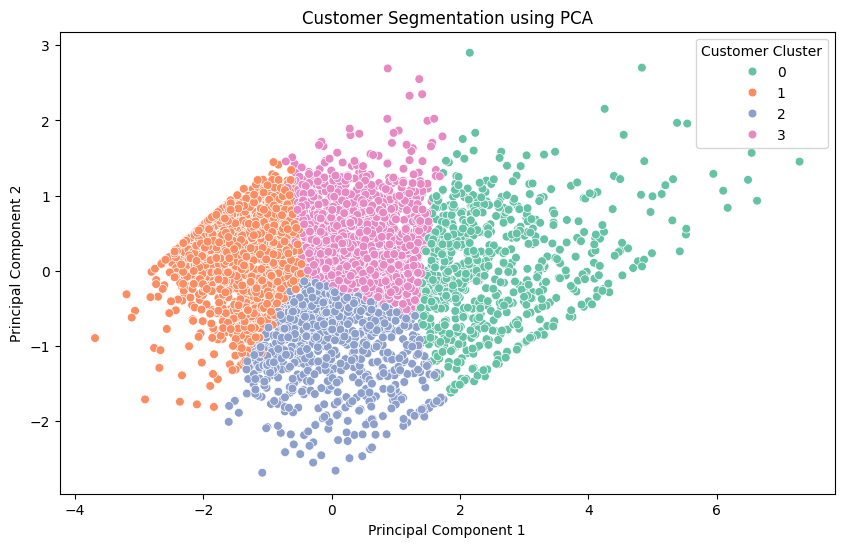

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=40
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")

plt.show()